# 🛒 Análisis de ventas y clientes de un e-commerce (Olist)

Este notebook responde preguntas de negocio sobre las ventas, las categorías de
producto y la logística de entrega de **Olist**, un marketplace de Brasil.

**Fuente de datos:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle), cargado en una base SQLite (`olist.db`).

**Criterios del análisis**
- **Periodo:** enero de 2017 a agosto de 2018. Se excluyen los meses con muy pocos pedidos (2016 y septiembre-octubre de 2018).
- **Pedidos considerados:** solo los que tienen estado `delivered`.
- **Definición de venta:** suma del precio de los productos, sin incluir el flete.
- **Moneda:** reales brasileños (R$).

## Configuración y conexión a los datos

Se importan las librerías de análisis (pandas), visualización (matplotlib y
seaborn) y se abre la conexión a la base de datos SQLite. Las consultas SQL se
ejecutan desde Python con `pandas.read_sql_query`.

In [7]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
conn = sqlite3.connect("../olist.db")

## 1. Evolución de las ventas

**Pregunta de negocio:** ¿cómo evolucionan las ventas mes a mes y cuándo se
alcanza el punto más alto?

Se agrupan las ventas por mes y se grafican, marcando el mes de mayor venta.

In [8]:
query = """
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS mes,
       COUNT(DISTINCT o.order_id) AS pedidos,
       ROUND(SUM(oi.price), 2) AS ventas
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY mes
ORDER BY mes;
"""
ventas = pd.read_sql_query(query, conn)
ventas.head()

,mes,pedidos,ventas
0,2017-01,750,111798.36
1,2017-02,1653,234223.40
2,2017-03,2546,359198.85
3,2017-04,2303,340669.68
4,2017-05,3546,489338.25


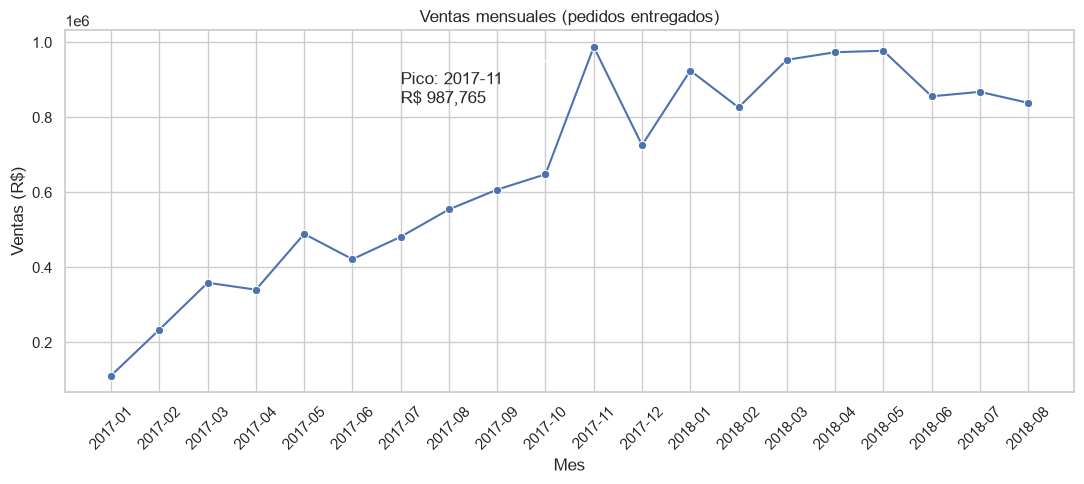

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=ventas, x="mes", y="ventas", marker="o", ax=ax)

idx = ventas["ventas"].idxmax()
ax.annotate(
    f"Pico: {ventas.loc[idx, 'mes']}\nR$ {ventas.loc[idx, 'ventas']:,.0f}",
    xy=(idx, ventas.loc[idx, "ventas"]),
    xytext=(idx - 4, ventas.loc[idx, "ventas"] - 150000),
    arrowprops=dict(arrowstyle="->"),
)

ax.set_title("Ventas mensuales (pedidos entregados)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ventas (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("../docs/images/ventas_mensuales.png", dpi=150)
plt.show()

### Conclusiones

- Las ventas crecen con fuerza durante 2017: de unos R$ 112 mil en enero a
  cerca de R$ 988 mil en noviembre.
- **Noviembre de 2017 es el pico del periodo** (+52 % frente a octubre), en línea
  con la temporada de Black Friday. Diciembre baja 26.5 %, un descenso estacional
  posterior al pico.
- En 2018 las ventas se mantienen en una **meseta alta** (entre R$ 826 mil y
  R$ 978 mil al mes), con una baja de 12.4 % en junio.

## 2. Categorías más vendidas

**Pregunta de negocio:** ¿qué categorías generan más ingresos y qué tan
concentradas están las ventas?

Se unen los pedidos con sus productos y con la tabla de traducción para mostrar
los nombres de las categorías en inglés. El gráfico muestra las 10 con mayores ventas.

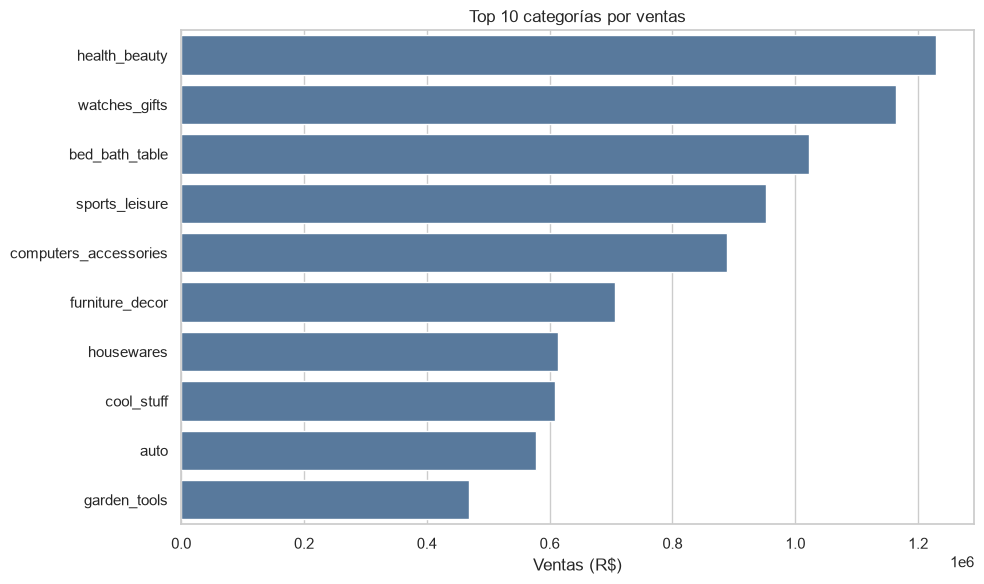

In [10]:
query_cat = """
SELECT COALESCE(t.product_category_name_english,
                p.product_category_name,
                'sin_categoria') AS categoria,
       ROUND(SUM(oi.price), 2) AS ventas
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t
       ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY categoria
ORDER BY ventas DESC
LIMIT 10;
"""
categorias = pd.read_sql_query(query_cat, conn)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=categorias, x="ventas", y="categoria", ax=ax, color="#4C78A8")
ax.set_title("Top 10 categorías por ventas")
ax.set_xlabel("Ventas (R$)")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig("../docs/images/top_categorias.png", dpi=150)
plt.show()

### Conclusiones

- Las categorías líderes son `health_beauty`, `watches_gifts` y `bed_bath_table`,
  que juntas suman cerca del 26 % de las ventas.
- Los ingresos están **diversificados**: ninguna categoría supera el 10 %, las 5
  primeras concentran ~40 % y las 10 primeras ~62 %.
- Volumen y valor no coinciden: `bed_bath_table` vende más unidades pero queda
  tercera por su precio bajo, mientras que `watches_gifts` es segunda con menos
  unidades gracias a un precio promedio alto.

## 3. Logística y satisfacción del cliente

**Pregunta de negocio:** ¿los retrasos en la entrega afectan la calificación que
dan los clientes?

Se compara la fecha real de entrega con la fecha estimada y se agrupan los
pedidos en tres niveles de puntualidad. Luego se calcula la calificación promedio
(1 a 5) de cada grupo. Se consideran solo pedidos con reseña, y si un pedido tiene
varias, se usa el promedio.

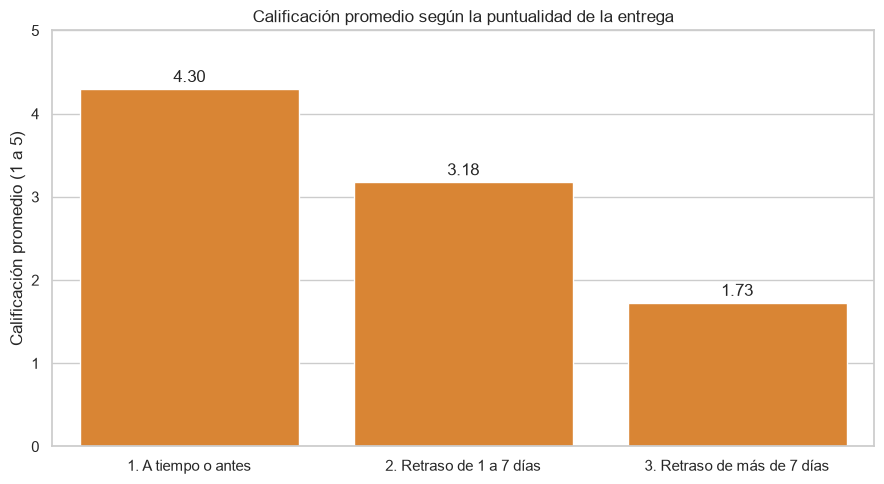

In [11]:
query_log = """
WITH entregas AS (
    SELECT order_id,
           julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp) AS dias_entrega,
           julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date) AS dias_retraso
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp <  '2018-09-01'
),
resenas AS (
    SELECT order_id, AVG(review_score) AS puntaje
    FROM order_reviews
    GROUP BY order_id
)
SELECT CASE
           WHEN e.dias_retraso <= 0 THEN '1. A tiempo o antes'
           WHEN e.dias_retraso <= 7 THEN '2. Retraso de 1 a 7 días'
           ELSE '3. Retraso de más de 7 días'
       END AS puntualidad,
       COUNT(*) AS pedidos,
       ROUND(AVG(r.puntaje), 2) AS puntaje_prom
FROM entregas e
JOIN resenas r ON e.order_id = r.order_id
GROUP BY puntualidad
ORDER BY puntualidad;
"""
logistica = pd.read_sql_query(query_log, conn)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=logistica, x="puntualidad", y="puntaje_prom", ax=ax, color="#F58518")
ax.set_title("Calificación promedio según la puntualidad de la entrega")
ax.set_xlabel("")
ax.set_ylabel("Calificación promedio (1 a 5)")
ax.set_ylim(0, 5)
for i, v in enumerate(logistica["puntaje_prom"]):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center")
plt.tight_layout()
fig.savefig("../docs/images/puntualidad_calificacion.png", dpi=150)
plt.show()

### Conclusiones

- El **92 %** de los pedidos llega a tiempo o antes de la fecha estimada.
- La calificación baja de **4.30** (a tiempo) a **3.18** con retrasos de hasta una
  semana y a **1.73** con retrasos mayores, una caída cercana al 60 %.
- Aunque solo el 3.4 % de los pedidos sufre un retraso grave, es el grupo con la
  peor experiencia, por lo que reducir esos casos sería la principal palanca para
  mejorar la satisfacción.
- **Limitación:** es una asociación, no una causalidad; un retraso puede coincidir
  con otros problemas, como productos dañados.

## Conclusiones generales y próximos pasos

1. El negocio creció con fuerza en 2017 y se estabilizó en 2018, con un pico
   estacional en noviembre.
2. Las ventas están repartidas entre muchas categorías, sin dependencia de una sola.
3. Cumplir la fecha de entrega es clave para la satisfacción del cliente.
4. La retención es la gran oportunidad: el 97 % de los clientes compra una sola
   vez, y el 74 % de las ventas viene de los clientes de mayor gasto.

**Próximo paso:** dashboard interactivo en Power BI.

## 4. Segmentación de clientes (RFM adaptado)

**Pregunta de negocio:** ¿qué clientes aportan más ingresos y cuáles conviene
retener o reactivar?

Se puntúa a cada cliente del 1 al 5 según su **recencia** (días desde su última
compra hasta el 01/09/2018) y su **monto** gastado. Como el 97 % de los clientes
compró una sola vez, la **frecuencia** no los diferencia y se usa solo para
identificar a los recurrentes. Las reglas de segmentación se evalúan en orden.

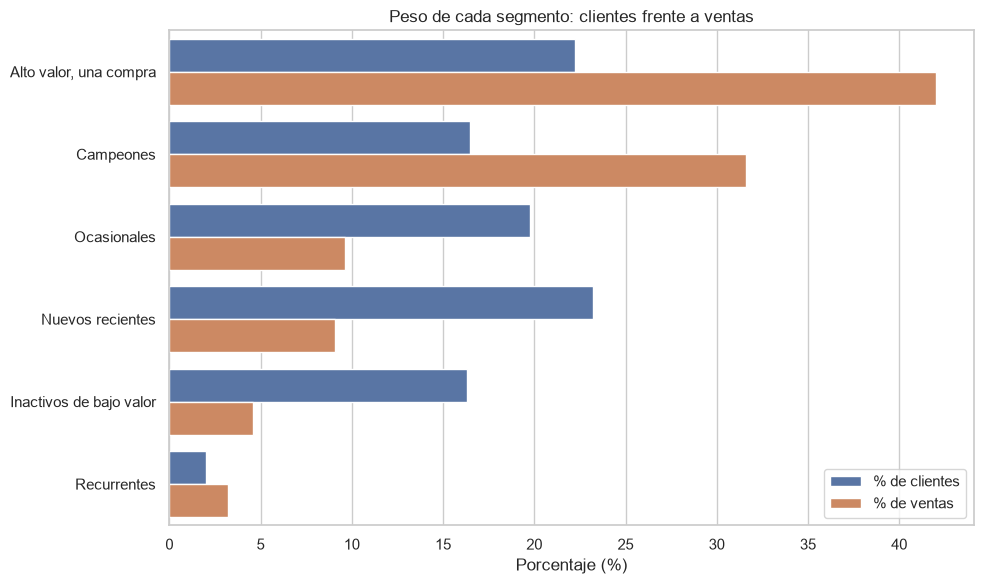

In [12]:
query_rfm = """
WITH base AS (
    SELECT c.customer_unique_id,
           MAX(o.order_purchase_timestamp) AS ultima_compra,
           COUNT(DISTINCT o.order_id) AS frecuencia,
           SUM(oi.price) AS monetario
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY c.customer_unique_id
),
puntajes AS (
    SELECT customer_unique_id,
           CAST(julianday('2018-09-01') - julianday(ultima_compra) AS INTEGER) AS recencia_dias,
           frecuencia,
           monetario,
           NTILE(5) OVER (ORDER BY ultima_compra ASC) AS r_score,
           NTILE(5) OVER (ORDER BY monetario ASC) AS m_score
    FROM base
),
segmentos AS (
    SELECT customer_unique_id, recencia_dias, frecuencia, monetario,
           CASE
               WHEN r_score >= 4 AND m_score >= 4 THEN 'Campeones'
               WHEN frecuencia >= 2 THEN 'Recurrentes'
               WHEN m_score >= 4 THEN 'Alto valor, una compra'
               WHEN r_score >= 4 THEN 'Nuevos recientes'
               WHEN r_score <= 2 AND m_score <= 2 THEN 'Inactivos de bajo valor'
               ELSE 'Ocasionales'
           END AS segmento
    FROM puntajes
)
SELECT segmento,
       COUNT(*) AS clientes,
       ROUND(SUM(monetario), 2) AS ventas,
       ROUND(SUM(monetario) * 100.0 / SUM(SUM(monetario)) OVER (), 1) AS pct_ventas,
       ROUND(AVG(monetario), 2) AS gasto_promedio,
       ROUND(AVG(recencia_dias), 0) AS recencia_promedio_dias
FROM segmentos
GROUP BY segmento
ORDER BY ventas DESC;
"""
rfm = pd.read_sql_query(query_rfm, conn)
rfm["pct_clientes"] = rfm["clientes"] / rfm["clientes"].sum() * 100

datos = rfm.melt(id_vars="segmento",
                 value_vars=["pct_clientes", "pct_ventas"],
                 var_name="medida", value_name="porcentaje")
datos["medida"] = datos["medida"].map({"pct_clientes": "% de clientes",
                                        "pct_ventas": "% de ventas"})

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=datos, x="porcentaje", y="segmento", hue="medida", ax=ax)
ax.set_title("Peso de cada segmento: clientes frente a ventas")
ax.set_xlabel("Porcentaje (%)")
ax.set_ylabel("")
ax.legend(title="")
plt.tight_layout()
fig.savefig("../docs/images/segmentos_rfm.png", dpi=150)
plt.show()

### Conclusiones

- Los segmentos **Alto valor, una compra** y **Campeones** (39 % de los clientes)
  generan el **73.6 % de las ventas**.
- **Alto valor, una compra** es la mayor oportunidad: gastaron en promedio R$ 267
  pero llevan casi un año sin volver. Son candidatos a campañas de reactivación.
- **Nuevos recientes** es el grupo más numeroso pero de bajo gasto (R$ 56): el
  objetivo sería impulsar una segunda compra.
- El segmento **Recurrentes** (1,863) excluye a 926 recurrentes que caen en
  Campeones, porque esa regla se evalúa primero.
- Las acciones propuestas son hipótesis a validar, no resultados.